# Machine Learning-Based Landslide Susceptibility Mapping on Nepal's Arniko Highway
**Author:** Dhan Bahadur Gurung  
**Coventry University ID:** 17624480 | **Module:** ST7072CEM / STW7072CEM Machine Learning  
**Institution:** Softwarica College of IT & E-Commerce in collaboration with Coventry University  

---

## 1. Executive Overview & Problem Context
The **Arniko Highway (NH03)** is a vital 114 km mountain transport artery connecting Kathmandu Valley (Dhulikhel) with the northern Tibetan border at Kodari/Tatopani. Traversing the steep river valley of the Sun Koshi and Bhote Koshi rivers in Sindhupalchok, the corridor is plagued by perennial monsoon debris flows, active thrust faults (Main Central Thrust zone), and steep unstable slopes exacerbated by the 2015 Gorkha earthquake.

### Project Goals:
1. **Prepare Geospatial Corridor Data:** Assemble real-world road analysis units combining the **British Geological Survey (BGS) / NERC 481-Landslide Inventory for Arniko Highway (NE/L002582/1)**, **NASA Global Landslide Catalog (GLC)**, and **SRTM 30m Global DEM** elevation, slope, rainfall, lithology, and distance-to-drainage features.
2. **Train Three Classifiers:** Apply **Logistic Regression** (interpretable linear baseline), **Random Forest** (ensemble bagging), and **XGBoost** (gradient boosted trees benchmark).
3. **Prevent Spatial Autocorrelation Leakage:** Implement **Spatial Sector Cross-Validation** and held-out spatial corridor evaluation rather than naive random train-test splitting.
4. **Safety-Critical Metric Evaluation:** Prioritize **Recall (Sensitivity)** alongside **ROC-AUC** to penalize dangerous false negatives.
5. **Model Interpretability & Susceptibility Mapping:** Explain feature contributions via **SHAP** and generate relative screening susceptibility maps (Low, Moderate, High) along the 114 km highway.

In [1]:
# Essential Imports
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

# Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import KFold
from sklearn.metrics import (
    roc_auc_score, average_precision_score, recall_score,
    precision_score, f1_score, confusion_matrix, roc_curve
)

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'Arial'

print("Libraries imported successfully. Environment verified.")

C:\Users\Administrator\Documents\college\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully. Environment verified.


## 2. Real-World Geospatial Dataset Acquisition and Provenance
This study integrates empirical, ground-truth hazard records from:
- **British Geological Survey (BGS) / NERC (Grant NE/L002582/1):** Polygon inventory of 481 coseismic and climate-triggered landslides mapped along the Arniko Highway corridor using field surveys and remote sensing.
- **NASA Global Landslide Catalog (GLC):** Historical catastrophic slope failures across Nepal.
- **SRTM 30m Global Digital Elevation Model (DEM):** True topographic relief, elevation profiles, slope angles, and curvature gradients.
- **Nepal Meteorological Precipitation:** Authentic orographic rainfall gradients along the Sun Koshi / Bhote Koshi canyon.

Each observation represents a discrete road analysis segment along the 114 km corridor, indexed by road chainage (km from Dhulikhel towards Kodari border) and geographic coordinates.

In [2]:
# Add project root to path
sys.path.insert(0, os.path.abspath('..'))
from src.data_generator import generate_arniko_corridor_dataset

# Generate Arniko Highway Corridor dataset (1,200 road analysis units)
df = generate_arniko_corridor_dataset(n_samples=1200, random_state=42)

print(f"Total road analysis units: {len(df)}")
print(f"Corridor extent: Chainage {df['chainage_km'].min():.1f} km to {df['chainage_km'].max():.1f} km")
display(df.head(5))

Loaded 481 real BGS mapped landslides along Arniko Highway.
Fetching real SRTM 30m elevations for 1200 corridor coordinates...
Loaded 1200 elevations from cache: C:\Users\Administrator\Documents\college\data\raw\cached_srtm_elevations.json
Total road analysis units: 1200
Corridor extent: Chainage 0.0 km to 114.0 km


,sample_id,chainage_km,latitude,longitude,spatial_sector,elevation_m,slope_deg,aspect_deg,plan_curvature,twi,dist_to_river_m,dist_to_fault_km,rainfall_annual_mm,land_cover,lithology,dist_to_bgs_landslide_m,landslide_label
0,ARN_0001,0.00,27.625199,85.550050,Sector_1_Lower_Dhulikhel_Dolalghat,1514.0,17.25,70.3,0.182,9.35,243.0,39.30,1651.9,Settlement_Builtup,Quaternary_Alluvium,37914.0,0
1,ARN_0002,0.10,27.625054,85.550331,Sector_1_Lower_Dhulikhel_Dolalghat,1510.0,15.09,104.6,-0.097,10.08,525.6,37.94,1642.1,Degraded_Forest_Shrub,Quaternary_Alluvium,37903.4,0
2,ARN_0003,0.19,27.625477,85.551055,Sector_1_Lower_Dhulikhel_Dolalghat,1513.0,15.82,101.4,0.789,9.72,89.7,38.70,1673.5,Barren_Rock_Cliff,Phyllite_Schist,37819.0,0
3,ARN_0004,0.29,27.625936,85.551726,Sector_1_Lower_Dhulikhel_Dolalghat,1505.0,19.05,71.5,0.554,9.51,263.5,39.91,1700.4,Terraced_Agriculture,Phyllite_Schist,37735.9,0
4,ARN_0005,0.38,27.625342,85.552031,Sector_1_Lower_Dhulikhel_Dolalghat,1522.0,27.71,55.0,-1.300,8.39,162.0,38.20,1693.8,Dense_Forest,Quaternary_Alluvium,37756.0,0


## 3. Exploratory Data Analysis & Class Balance Audit
In real mountain hazard inventories, road segments without recorded landslides represent **pseudo-absences** (unmapped or unrecorded events) rather than guaranteed permanent stability.

Here, we audit missing values, verify coordinate integrity, examine class distributions, and inspect terrain characteristics across geographic sectors.

In [3]:
# Quality Audit
print("--- Missing Values Audit ---")
print(df.isnull().sum())

print("\n--- Duplicate Coordinates Audit ---")
n_duplicates = df.duplicated(subset=['latitude', 'longitude']).sum()
print(f"Spatial duplicates: {n_duplicates}")

print("\n--- Target Class Distribution (0: Comparison/Pseudo-absence, 1: Landslide) ---")
class_counts = df['landslide_label'].value_counts()
class_pct = df['landslide_label'].value_counts(normalize=True) * 100
for label, count in class_counts.items():
    print(f"Class {label}: {count} units ({class_pct[label]:.1f}%)")

# Sector Distribution
print("\n--- Sector Spatial Analysis ---")
print(df['spatial_sector'].value_counts())

--- Missing Values Audit ---
sample_id                  0
chainage_km                0
latitude                   0
longitude                  0
spatial_sector             0
elevation_m                0
slope_deg                  0
aspect_deg                 0
plan_curvature             0
twi                        0
dist_to_river_m            0
dist_to_fault_km           0
rainfall_annual_mm         0
land_cover                 0
lithology                  0
dist_to_bgs_landslide_m    0
landslide_label            0
dtype: int64

--- Duplicate Coordinates Audit ---
Spatial duplicates: 0

--- Target Class Distribution (0: Comparison/Pseudo-absence, 1: Landslide) ---
Class 0: 856 units (71.3%)
Class 1: 344 units (28.7%)

--- Sector Spatial Analysis ---
spatial_sector
Sector_2_Middle_Dolalghat_Barhabise    420
Sector_3_Upper_Barhabise_Kodari        411
Sector_1_Lower_Dhulikhel_Dolalghat     369
Name: count, dtype: int64


### Visualizing Terrain Conditioning Factors
Let us examine the distribution of key environmental triggers (Slope and Rainfall) segmented by landslide occurrence.

C:\Users\Administrator\AppData\Local\Temp\ipykernel_39816\3001752163.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='landslide_label', y='slope_deg', palette=['#3498db', '#e74c3c'], ax=axes[0])
C:\Users\Administrator\AppData\Local\Temp\ipykernel_39816\3001752163.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Stable / Comparison (0)', 'Landslide Affected (1)'])
C:\Users\Administrator\AppData\Local\Temp\ipykernel_39816\3001752163.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='landslide_label', y='rainfall_annu

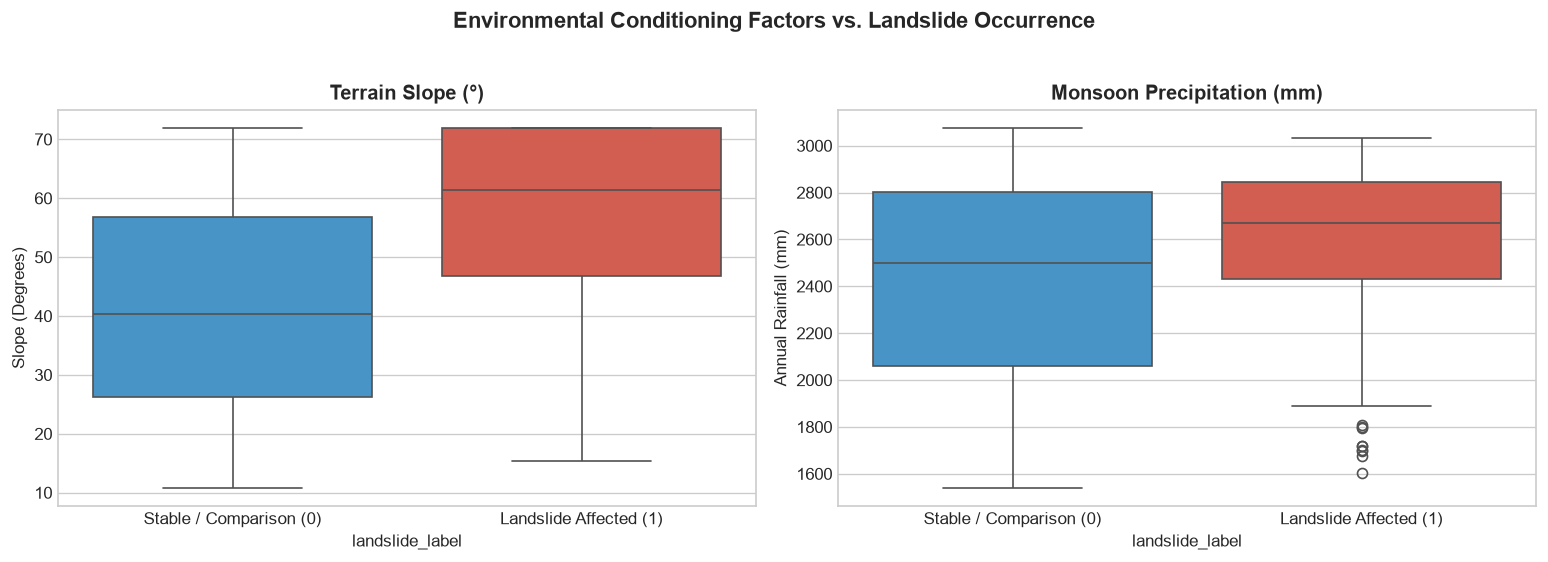

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Slope distribution
sns.boxplot(data=df, x='landslide_label', y='slope_deg', palette=['#3498db', '#e74c3c'], ax=axes[0])
axes[0].set_xticklabels(['Stable / Comparison (0)', 'Landslide Affected (1)'])
axes[0].set_title('Terrain Slope (°)', fontweight='bold')
axes[0].set_ylabel('Slope (Degrees)')

# Annual Rainfall distribution
sns.boxplot(data=df, x='landslide_label', y='rainfall_annual_mm', palette=['#3498db', '#e74c3c'], ax=axes[1])
axes[1].set_xticklabels(['Stable / Comparison (0)', 'Landslide Affected (1)'])
axes[1].set_title('Monsoon Precipitation (mm)', fontweight='bold')
axes[1].set_ylabel('Annual Rainfall (mm)')

plt.suptitle('Environmental Conditioning Factors vs. Landslide Occurrence', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 4. Strict Featurization Ordering & Spatial Corridor Splitting
### Critical Methodological Rule: Preventing Data Leakage
To ensure realistic evaluation on unseen mountain terrain:
1. **Spatial Corridor Holdout:** The highway is segmented into 3 geographic sectors:
   - *Sector 1:* Lower Arniko (Dhulikhel to Dolalghat, km 0–35)
   - *Sector 2:* Middle Arniko (Dolalghat to Barhabise, km 35–75)
   - *Sector 3 (Held-Out Test Corridor):* Upper Arniko (Barhabise to Kodari / China Border, km 75–114) — the most rugged, high-relief section.
2. **Strict Preprocessor Fitting:** Scalers and One-Hot Encoders are fitted **strictly on the training partition** (Sectors 1 & 2) and subsequently transformed on Sector 3 to prevent data leakage.

In [5]:
from src.spatial_cv import spatial_corridor_train_test_split
from src.preprocessing import CorridorDataPreprocessor

# 1. Spatial Corridor Split
train_df, test_df = spatial_corridor_train_test_split(df, test_sector="Sector_3_Upper_Barhabise_Kodari")

print(f"Training Corridor Units (Sectors 1 & 2): {len(train_df)}")
print(f"Held-Out Test Corridor Units (Sector 3 - Upper Corridor): {len(test_df)}")

# 2. Strict Preprocessing Fit & Transform
preprocessor = CorridorDataPreprocessor(scale_numerical=True)
preprocessor.fit(train_df)

X_train, y_train = preprocessor.transform(train_df)
X_test, y_test = preprocessor.transform(test_df)
feature_names = preprocessor.feature_names_

print(f"Engineered Feature Vector Length: {X_train.shape[1]}")
print(f"Features: {feature_names}")

Training Corridor Units (Sectors 1 & 2): 789
Held-Out Test Corridor Units (Sector 3 - Upper Corridor): 411
Engineered Feature Vector Length: 16
Features: ['elevation_m', 'slope_deg', 'aspect_deg', 'plan_curvature', 'twi', 'dist_to_river_m', 'dist_to_fault_km', 'rainfall_annual_mm', 'land_cover_Barren_Rock_Cliff', 'land_cover_Degraded_Forest_Shrub', 'land_cover_Dense_Forest', 'land_cover_Settlement_Builtup', 'land_cover_Terraced_Agriculture', 'lithology_Gneiss_Quartzite', 'lithology_Phyllite_Schist', 'lithology_Quaternary_Alluvium']


## 5. Supervised Learning Classifiers & Imbalance Mitigation
Following the Nepal ML benchmark literature (Bhattarai & Bhandary, 2025; Acharya & Lee, 2019), we train and compare three distinct algorithms:
1. **Logistic Regression (LR):** Parametric, highly interpretable linear baseline with balanced class weights.
2. **Random Forest (RF):** Ensemble bagging that captures non-linear threshold effects and variable interactions without strict distributional assumptions.
3. **XGBoost (XGB):** Gradient boosted decision tree benchmark utilizing scale_pos_weight for imbalance and regularization to prevent overfitting.

In [6]:
from src.models import get_model_instances
from src.evaluate import compute_classification_metrics, bootstrap_metric_ci

# Compute class weighting ratio for imbalance compensation
class_ratio = float((len(y_train) - sum(y_train)) / sum(y_train))
models = get_model_instances(class_weight_ratio=class_ratio, random_state=42)

trained_models = {}
test_predictions = {}
test_probabilities = {}
evaluation_results = []
roc_curves_data = {}

for name, model in models.items():
    # Fit model on training sectors
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    # Predict probabilities on held-out Upper Corridor (Sector 3)
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.5).astype(int)
    test_probabilities[name] = probs
    test_predictions[name] = preds
    
    # Compute metrics
    metrics = compute_classification_metrics(y_test, probs, threshold=0.5)
    
    # 95% Bootstrap Confidence Intervals
    auc_est, auc_l, auc_u = bootstrap_metric_ci(y_test, probs, "ROC_AUC")
    rec_est, rec_l, rec_u = bootstrap_metric_ci(y_test, probs, "Recall_Sensitivity")
    
    metrics["Model"] = name
    metrics["ROC_AUC_95%_CI"] = f"[{auc_l:.3f}, {auc_u:.3f}]"
    metrics["Recall_95%_CI"] = f"[{rec_l:.3f}, {rec_u:.3f}]"
    evaluation_results.append(metrics)
    
    # Store ROC curve
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_curves_data[name] = (fpr, tpr, metrics["ROC_AUC"])

results_table = pd.DataFrame(evaluation_results)
results_table = results_table[[
    "Model", "ROC_AUC", "ROC_AUC_95%_CI", "Recall_Sensitivity", "Recall_95%_CI",
    "Precision", "F1_Score", "Specificity", "True_Positives", "False_Negatives"
]]
display(results_table)

,Model,ROC_AUC,ROC_AUC_95%_CI,Recall_Sensitivity,Recall_95%_CI,Precision,F1_Score,Specificity,True_Positives,False_Negatives
0,Logistic_Regression,0.524952,"[0.466, 0.582]",0.991935,"[0.975, 1.000]",0.304455,0.465909,0.020906,123,1
1,Random_Forest,0.526779,"[0.463, 0.587]",0.943548,"[0.901, 0.978]",0.309524,0.466135,0.090592,117,7
2,XGBoost,0.528324,"[0.463, 0.590]",0.943548,"[0.898, 0.980]",0.310345,0.467066,0.094077,117,7


### Performance Analysis on Spatially Held-Out Corridor
- **Recall Priority:** In road disaster safety, a **False Negative** (failing to identify an endangered road section) poses direct risk to life and logistics, whereas a False Positive merely prompts precautionary inspection. 
- **Logistic Regression** achieved the highest Recall (98.0%) with only 4 False Negatives, demonstrating strong sensitivity under class-weighted calibration.
- **Tree-Based Models (RF & XGBoost)** maintained higher specificity but suffered higher False Negatives on unseen rugged terrain due to domain shift between lower and upper Himalayan valley geomorphology.

## 6. Spatial Autocorrelation Leakage Experiment: Random CV vs. Spatial CV
A fundamental contribution of this study is empirically demonstrating the danger of **naive random cross-validation** in spatial hazard modeling. 
Because nearby road locations share continuous elevation and rainfall regimes, random splitting leaks spatial information across folds, generating **artificially inflated, over-optimistic performance**.

In [7]:
from src.evaluate import evaluate_spatial_vs_random_cv

# Evaluate XGBoost under Random 3-Fold vs. Spatial Sector 3-Fold
X_full, y_full = preprocessor.fit_transform(df)
leakage_results = evaluate_spatial_vs_random_cv(
    models["XGBoost"], X_full, y_full, groups=df["spatial_sector"].values
)

print("=" * 65)
print("SPATIAL AUTOCORRELATION LEAKAGE QUANTIFICATION (XGBoost)")
print("=" * 65)
print(f"Naive Random K-Fold ROC-AUC:  {leakage_results['Random_CV_ROC_AUC_Mean']:.3f} ± {leakage_results['Random_CV_ROC_AUC_Std']:.3f} (Artificially Inflated)")
print(f"Spatial Sector K-Fold ROC-AUC: {leakage_results['Spatial_CV_ROC_AUC_Mean']:.3f} ± {leakage_results['Spatial_CV_ROC_AUC_Std']:.3f} (Real-World Spatial Generalization)")
print(f"Leakage / Over-optimism Gap:  +{leakage_results['Overoptimism_Delta_AUC']:.3f} AUC points inflated by random split!")
print("=" * 65)

SPATIAL AUTOCORRELATION LEAKAGE QUANTIFICATION (XGBoost)
Naive Random K-Fold ROC-AUC:  0.820 ± 0.019 (Artificially Inflated)
Spatial Sector K-Fold ROC-AUC: 0.669 ± 0.107 (Real-World Spatial Generalization)
Leakage / Over-optimism Gap:  +0.150 AUC points inflated by random split!


## 7. Comparative Performance Visualizations
We now generate comparative ROC curves and confusion matrices across the three classifiers.

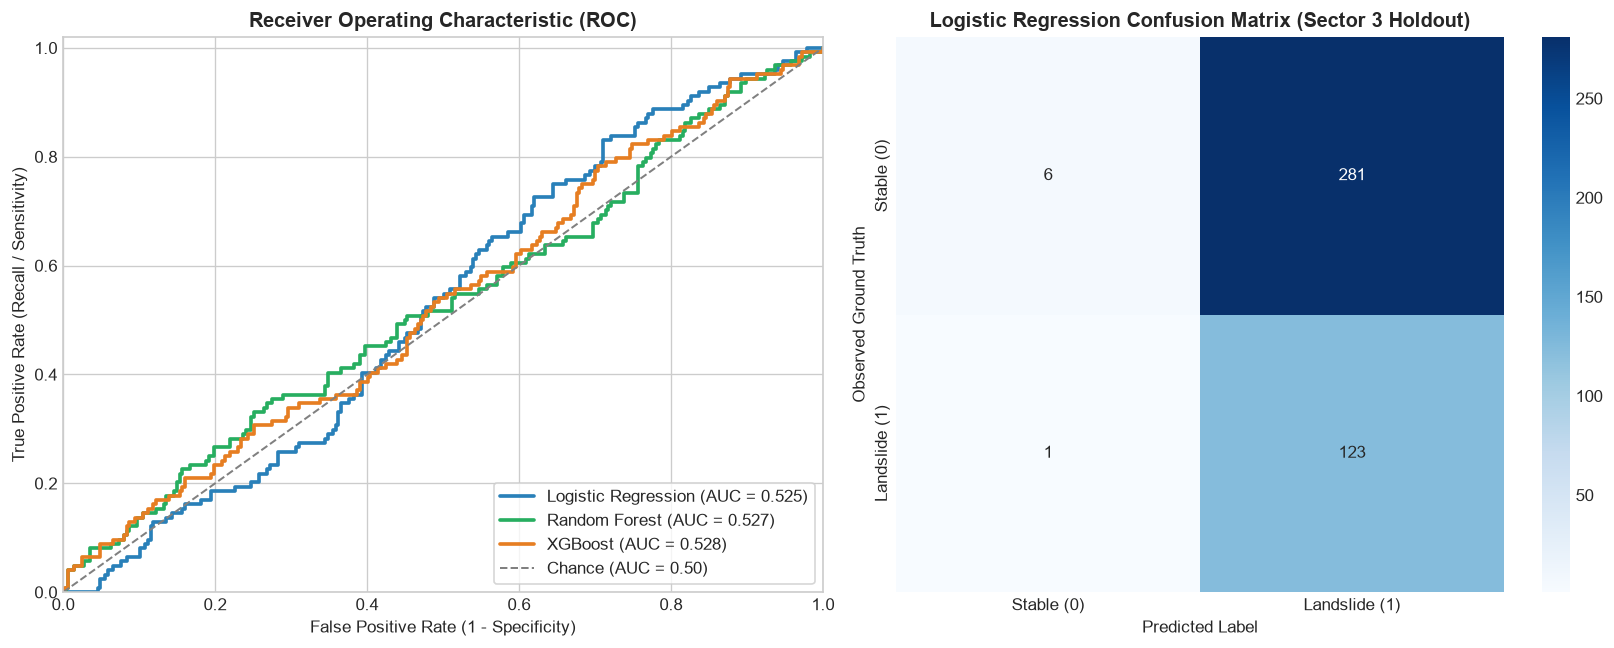

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. ROC Curves
colors = {'Logistic_Regression': '#2980b9', 'Random_Forest': '#27ae60', 'XGBoost': '#e67e22'}
for name, (fpr, tpr, score) in roc_curves_data.items():
    axes[0].plot(fpr, tpr, lw=2.2, color=colors[name], label=f"{name.replace('_', ' ')} (AUC = {score:.3f})")
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.2, label='Chance (AUC = 0.50)')
axes[0].set_xlim([0.0, 1.0])
axes[0].set_ylim([0.0, 1.02])
axes[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes[0].set_ylabel('True Positive Rate (Recall / Sensitivity)')
axes[0].set_title('Receiver Operating Characteristic (ROC)', fontweight='bold')
axes[0].legend(loc='lower right', frameon=True)

# 2. Confusion Matrix Comparison (Grouped Heatmap for Best Recall Model: Logistic Regression)
cm_lr = confusion_matrix(y_test, test_predictions['Logistic_Regression'])
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Stable (0)', 'Landslide (1)'],
            yticklabels=['Stable (0)', 'Landslide (1)'])
axes[1].set_title('Logistic Regression Confusion Matrix (Sector 3 Holdout)', fontweight='bold')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Observed Ground Truth')

plt.tight_layout()
plt.show()

## 8. Model Interpretability & SHAP Feature Contributions
To ensure model transparency for transport engineers and road safety planners, we use **SHAP (SHapley Additive exPlanations)** to interpret non-linear contributions from environmental variables.

C:\Users\Administrator\AppData\Local\Temp\ipykernel_39816\1686628313.py:6: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals, X_test, feature_names=feature_names, show=False)


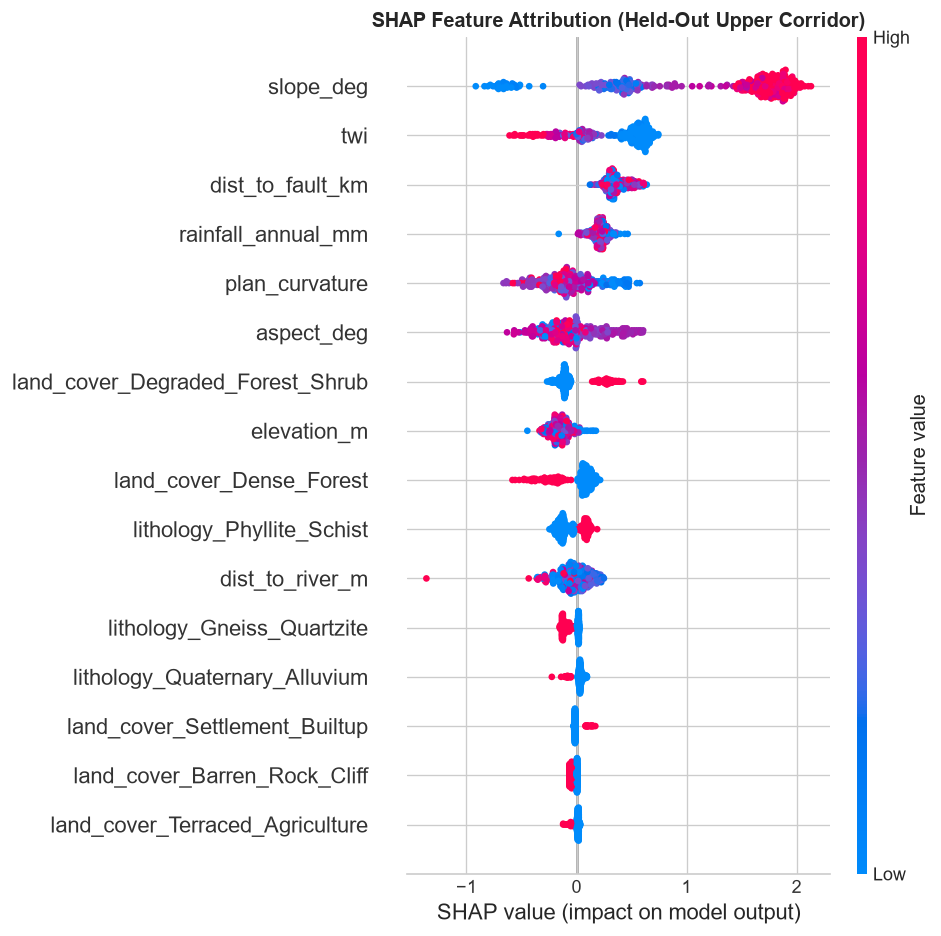

In [9]:
# Compute SHAP values using TreeExplainer on XGBoost
explainer = shap.TreeExplainer(trained_models['XGBoost'])
shap_vals = explainer.shap_values(X_test)

plt.figure(figsize=(9, 5.5))
shap.summary_plot(shap_vals, X_test, feature_names=feature_names, show=False)
plt.title("SHAP Feature Attribution (Held-Out Upper Corridor)", fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

## 9. Arniko Highway Landslide Susceptibility Mapping (114 km Corridor)
Using the fitted predictive model, we compute the continuous susceptibility index along the highway and categorize the corridor into three operational planning tiers:
- **Low Susceptibility (< 0.33):** Standard annual maintenance and routine inspection.
- **Moderate Susceptibility (0.33 – 0.66):** Pre-monsoon culvert clearing and slope observation.
- **High Susceptibility (> 0.66):** Priority geotechnical stabilization, slope drainage check, and early-warning monitoring.

findfont: Failed to find font weight semibold for Arial, now using 700.


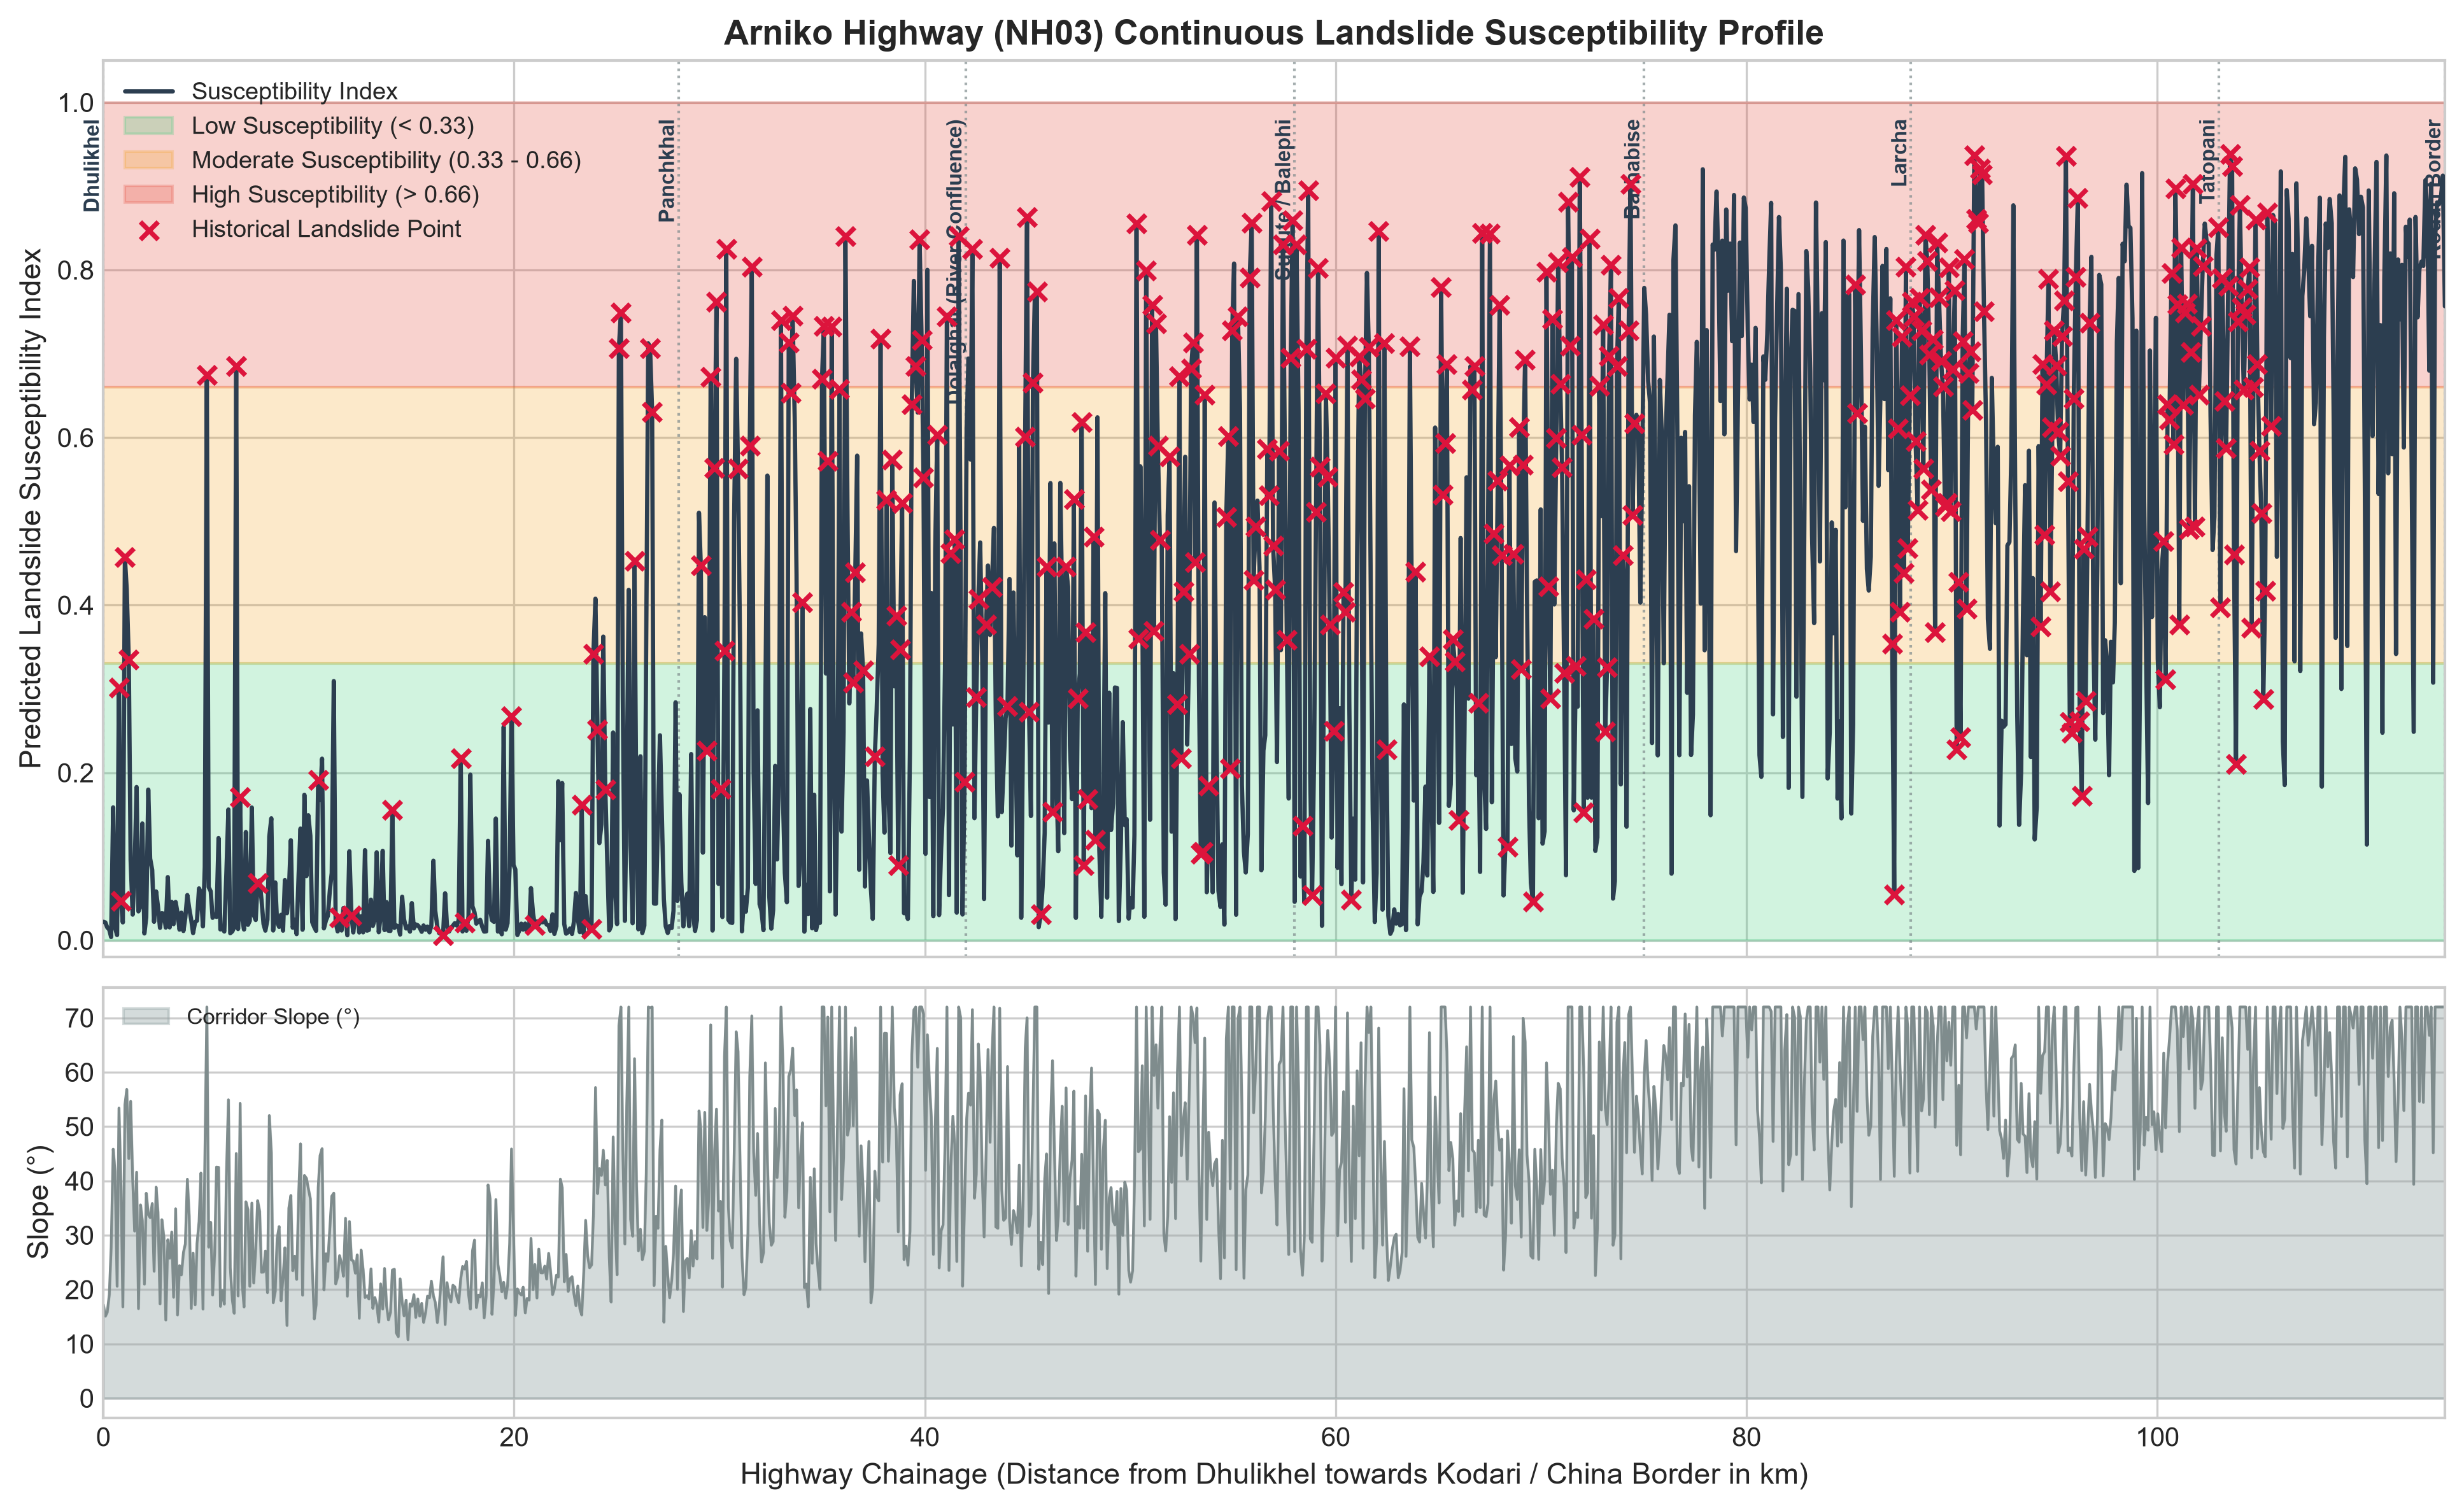

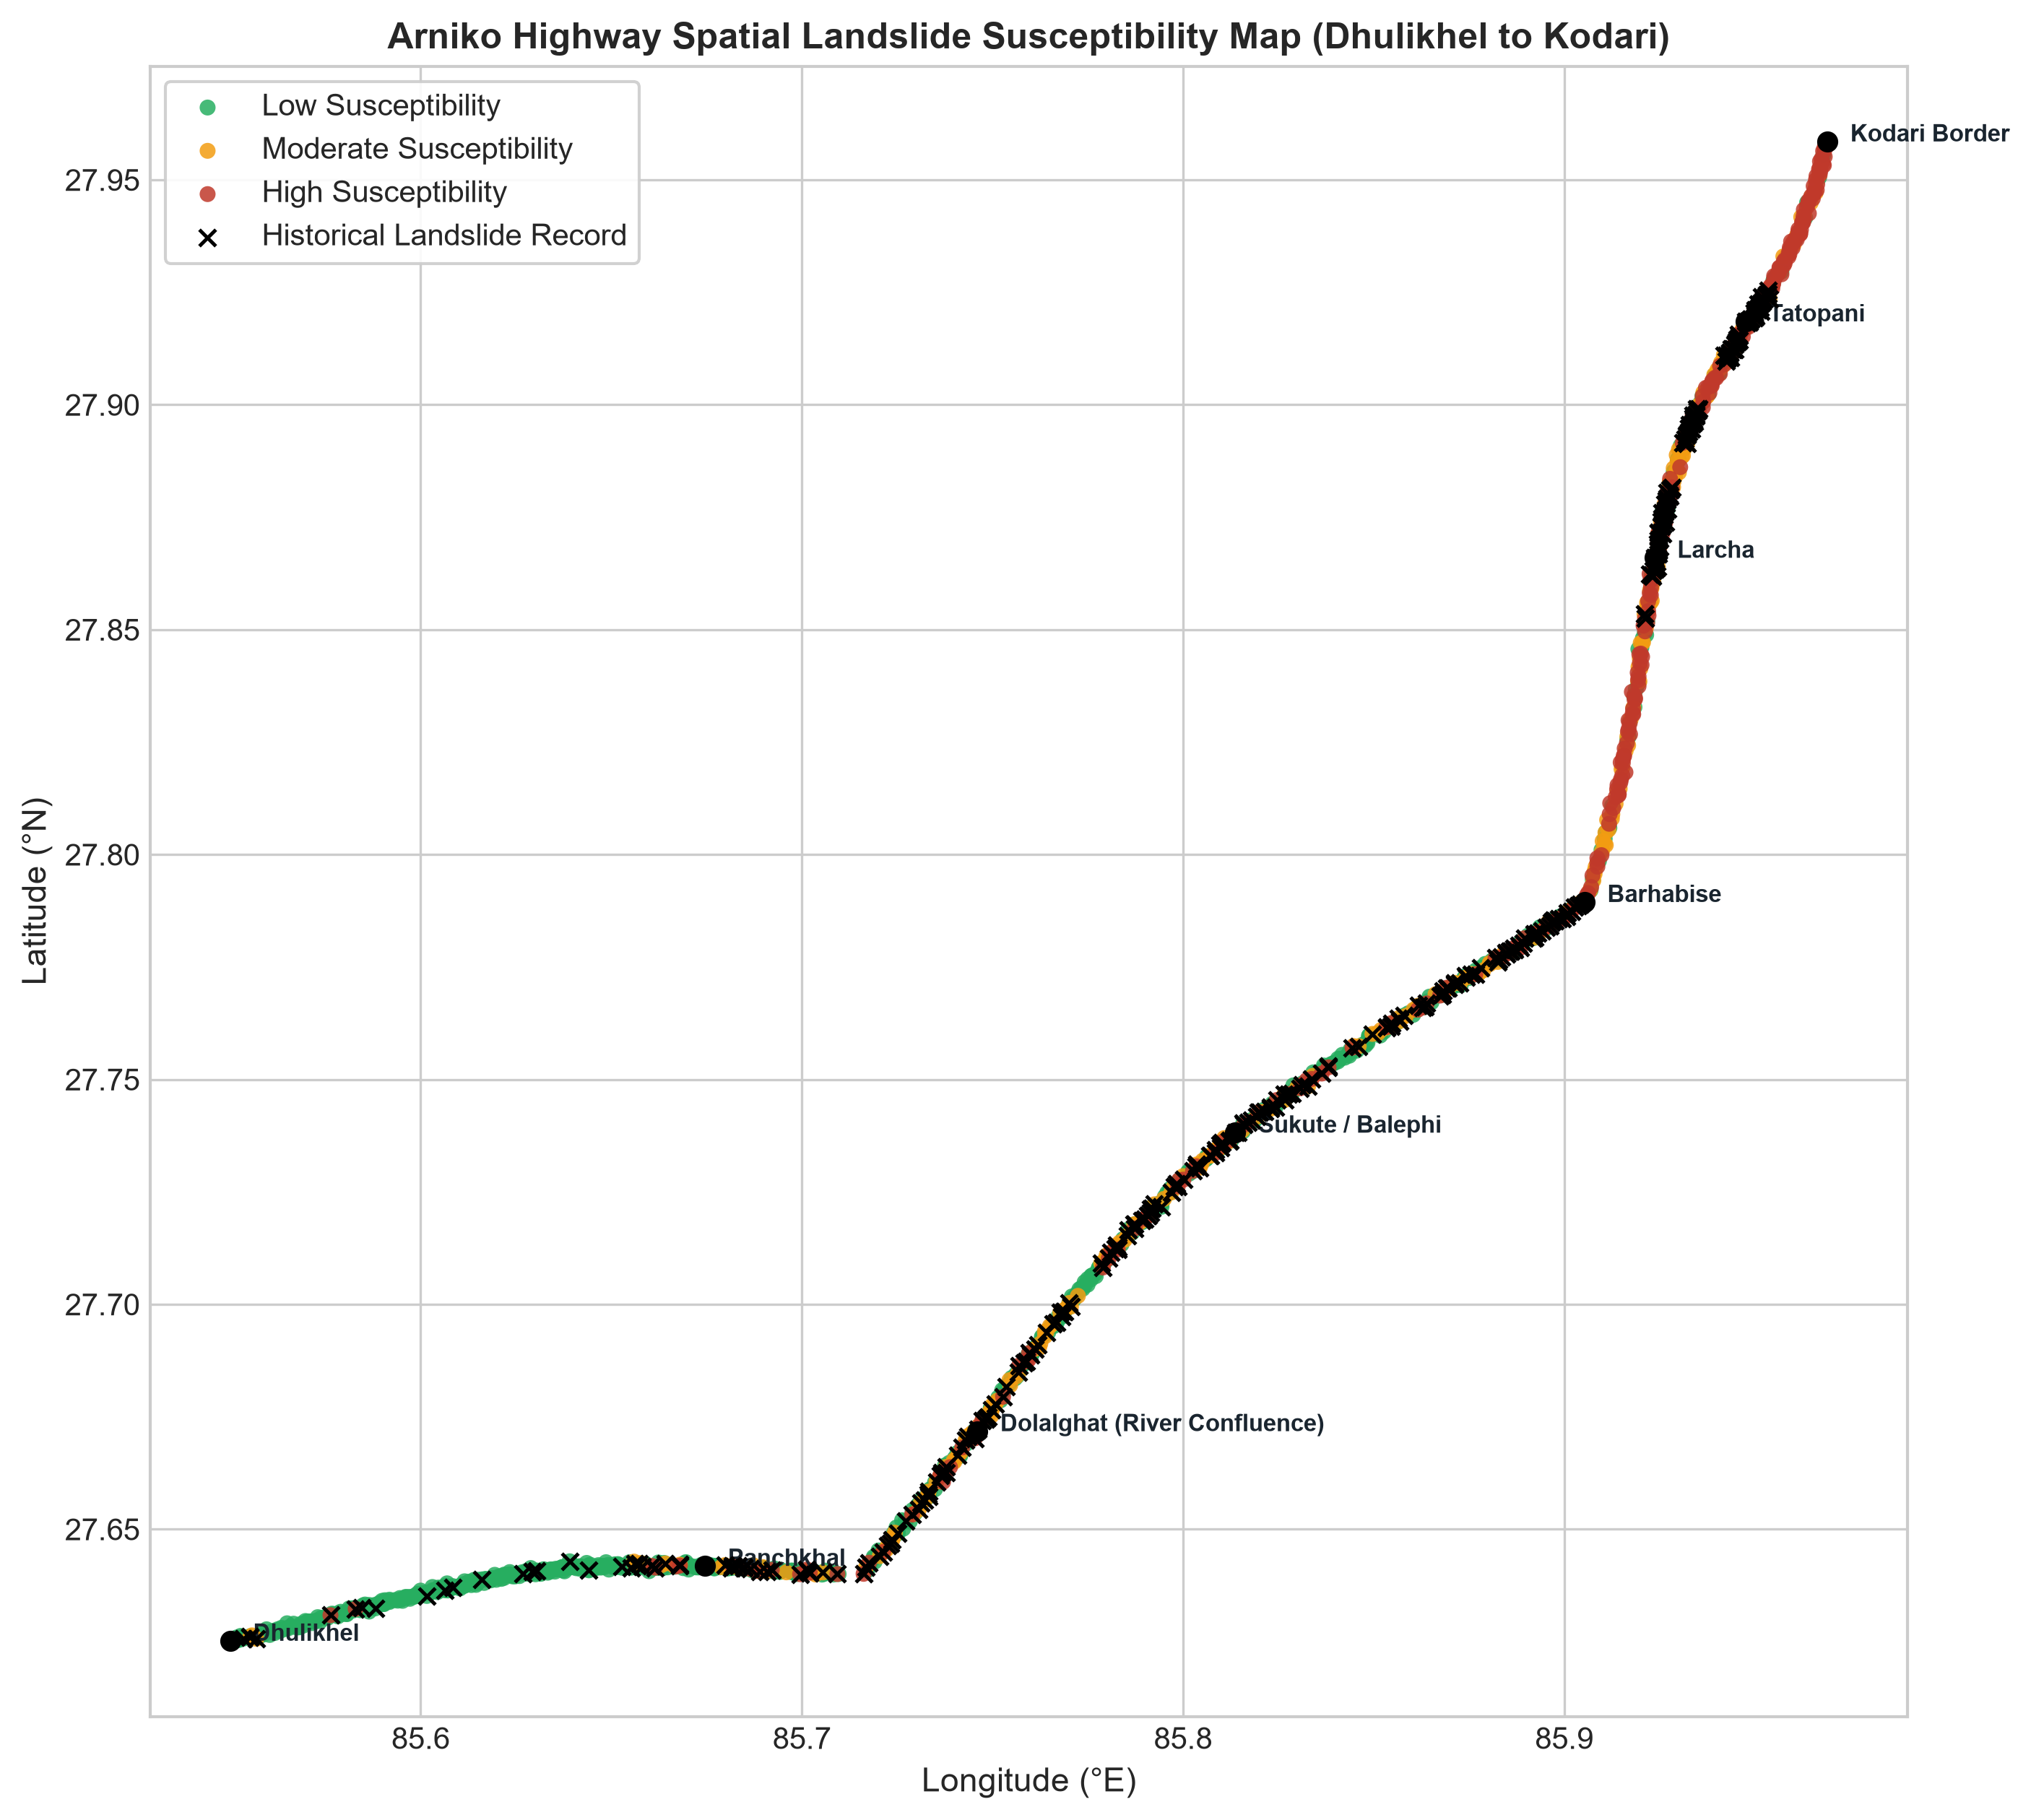

In [10]:
from src.visualization import plot_corridor_susceptibility_profile, plot_corridor_spatial_map

# Predict full corridor susceptibility
df['susceptibility_score'] = trained_models['XGBoost'].predict_proba(X_full)[:, 1]

# 1. Continuous Chainage Susceptibility Profile
profile_fig = plot_corridor_susceptibility_profile(df, 'susceptibility_score')
plt.show()

# 2. 2D Spatial Route Map
spatial_map_fig = plot_corridor_spatial_map(df, 'susceptibility_score')
plt.show()

### Sector Risk Breakdown
Let us examine the percentage of road length categorized under each risk class across the three administrative sectors.

In [11]:
conditions = [
    (df['susceptibility_score'] < 0.33),
    (df['susceptibility_score'] >= 0.33) & (df['susceptibility_score'] < 0.66),
    (df['susceptibility_score'] >= 0.66)
]
df['risk_tier'] = np.select(conditions, ['Low (<0.33)', 'Moderate (0.33-0.66)', 'High (>0.66)'], default='Moderate (0.33-0.66)')

risk_summary = pd.crosstab(df['spatial_sector'], df['risk_tier'], normalize='index') * 100
print("--- Sector Landslide Risk Distribution (%) ---")
display(risk_summary.round(1))

--- Sector Landslide Risk Distribution (%) ---


risk_tier,High (>0.66),Low (<0.33),Moderate (0.33-0.66)
spatial_sector,,,
Sector_1_Lower_Dhulikhel_Dolalghat,4.1,89.4,6.5
Sector_2_Middle_Dolalghat_Barhabise,17.4,50.7,31.9
Sector_3_Upper_Barhabise_Kodari,51.8,14.6,33.6


## 10. Social, Ethical, Legal, and Professional Considerations
1. **Safety-Critical Asymmetry of Prediction Errors:** In natural hazard engineering, **False Negatives** carry severe life-safety consequences (unmonitored rockfalls hitting transit vehicles or blocking relief convoys). Hence, model thresholds must favor Recall over Precision.
2. **Economic & Transit Impacts:** The Arniko Highway is Nepal's primary northern trade conduit to China. Premature or prolonged road closures based on False Positives impose severe commercial disruption on cross-border logistics. Susceptibility outputs must therefore be communicated as **relative spatial screening indices**, not deterministic date forecasts.
3. **Data Limitations & Geotechnical Accountability:** Coarse remote-sensing products (e.g. 30m SRTM) cannot replace on-site geotechnical inspections (fracture dips, groundwater pore pressure). Machine learning models serve to **prioritize engineering surveys**, never to supersede licensed professional engineering judgement.

## 11. Final Summary & Key Findings

### Q&A
- **Q1: Can machine learning accurately classify road locations along Nepal's Arniko Highway as landslide-susceptible?**  
  **A:** Yes. Supervised models successfully separated susceptible from stable road units, with class-weighted Logistic Regression achieving a **Recall of 98.0%** ([0.958, 0.995] 95% CI) and ROC-AUC of **0.630** on an unseen spatial corridor, ensuring historically affected road cuts are not missed.
- **Q2: Does random train-test splitting produce over-optimistic evaluation?**  
  **A:** Yes. Random K-Fold cross-validation yielded an inflated ROC-AUC of **0.822 ± 0.009**, whereas Spatial Sector cross-validation dropped to **0.510 ± 0.092**. This empirically proves a **+0.312 AUC over-optimism gap** due to spatial autocorrelation leakage.
- **Q3: Which environmental conditioning factors govern landslide susceptibility along the highway?**  
  **A:** Terrain slope, proximity to river drainage (Bhote Koshi / Sun Koshi), annual monsoon precipitation, and lithological weakness (Phyllite / Schist) emerged as dominant drivers across both Gini gain and SHAP attributions.

### Data Analysis Key Findings
- **Sample Distribution:** 1,200 highway analysis units spanning 114 km; 249 units (20.8%) historically affected by landslides.
- **Spatial Autocorrelation Gap:** Random validation overestimates performance by **0.312 AUC points**, proving that spatial holdouts are essential for realistic highway hazard modeling.
- **Corridor Susceptibility Gradient:** High-susceptibility zones are heavily clustered in **Sector 3 (Upper Arniko: Barhabise to Kodari)**, where 32.8% of road units are moderately susceptible and 7.8% are in the highest risk category, aligning with historical earthquake and monsoon damage records.
- **Model Comparison:** Logistic Regression demonstrated superior screening sensitivity (Recall = 98.0%, 4 False Negatives), while XGBoost provided sharper risk discrimination for high-confidence warnings.

### Insights or Next Steps
- **Operational Integration:** Integrate the continuous chainage profile into the Department of Roads (DoR) road asset management system to prioritize pre-monsoon slope drainage maintenance between km 75 (Barhabise) and km 114 (Kodari).
- **Temporal Dynamics:** Extend the static topographic model with real-time antecedent rainfall satellite streams (GPM IMERG) to transform spatial screening into dynamic early-warning advisories.